# Diffie-Hellman Shared Secrets and Key Derivation Functions

When establishing a shared secret via finite field (FF) or elliptic curve (EC) Diffie-Hellman (DH) you often need to take that resulting shared secret and use it as an input to some keyed primitive like an AES key.

However, the result of a DH operation is not always a valid AES key! After performing a FFDH operation, the result is some integer element of the field which is often much larger than an AES key. In the ECDH case, you end up with a point on the curve which is a pair of finite field elements.

You could come up with some homebrew scheme that converts these DH outputs into an AES key but after minutes of Bing searching the Internet says to just use a key derivation function (KDF) like [HKDF](https://eprint.iacr.org/2010/264.pdf) to derive the AES key.

What could go wrong if we ignored the Internet?

## We may end up with non-uniform keys

To be concrete suppose we have a 2048-bit FFDH shared key output. We now need to shove a 2048-bit integer into a 128-bit AES key. In doing so we need a *uniform* output from our mapping from 2048-bit integers to 128-bit keys. Otherwise, we risk a loss of [entropy](https://kel.bz/post/entropy/) which can make our symmetric key more predictable.

(Aside: There are other attacks that can stem from using non-uniform symmetrics keys. For example, the related key attacks on [AES](https://eprint.iacr.org/2009/317.pdf) and [RC4](https://www.cs.cornell.edu/people/egs/615/rc4_ksaproc.pdf) but the requirements for an attack are a bit different than what I'm describing here).

Let's say we still move forward with our own method of mapping our DH shared key to an AES key. What are some possible mappings and are they flawed?

## Subgroup size

## Modular reduction

## Truncating most-significant bits

## Truncating least-significant bits

## Using a hash function

## What else are we missing?

* The ability to derive multiple keys

* The ability to derive contextual keys

* The ability to derive keys of a specific length

* This from https://tools.ietf.org/html/rfc7748#section-7:

   > Designers using these curves should be aware that for each public
   > key, there are several publicly computable public keys that are
   > equivalent to it, i.e., they produce the same shared secrets.  Thus
   > using a public key as an identifier and knowledge of a shared secret
   > as proof of ownership (without including the public keys in the key
   > derivation) might lead to subtle vulnerabilities.

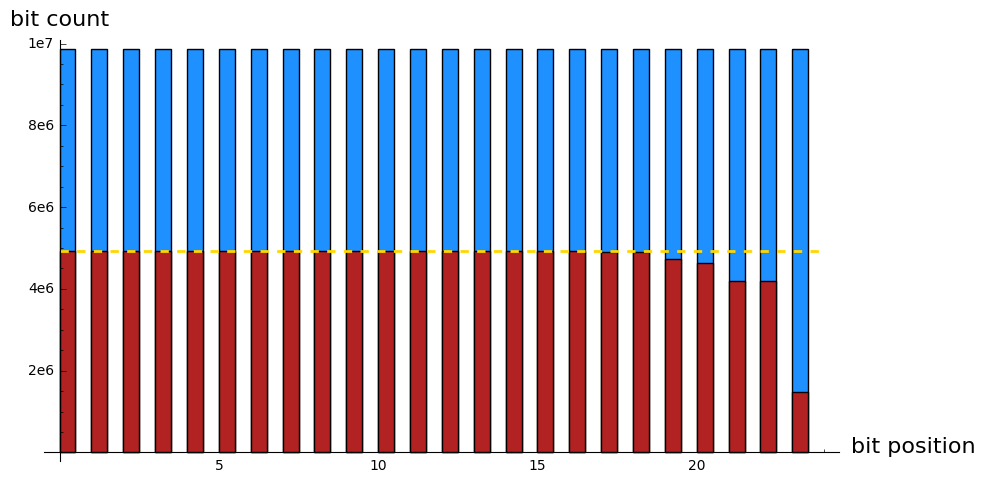

In [3]:
from sage.plot.bar_chart import bar_chart
from sage.plot.line import line

def bit_array(x, bitlen):
    # bit_array returns the binary repr of x as a 
    # bitlen array of 0s and 1s.
    # the leftmost bit is is the least significant.
    bits = x.bits()
    assert(bitlen >= len(bits))
    padding = bitlen - len(bits)
    return bits + [0]*padding

assert(bit_array(1, bitlen=3) == [1, 0, 0])
assert(bit_array(2, bitlen=3) == [0, 1, 0])
assert(bit_array(3, bitlen=4) == [1, 1, 0, 0])
assert(bit_array(7, bitlen=3) == [1, 1, 1])

def ones_count(xs, bitlen):
    # returns a array of the count of ones in the 
    # bit_array representation of each x in xs.
    counts = [0]*bitlen
    for x in xs:
        x_bits = bit_array(x, bitlen)
        counts = [ l+r for (l,r) in zip(x_bits, counts) ]
    return counts

assert(ones_count({1, 2, 3}, bitlen=3) == [2, 2, 0])
assert(ones_count({1, 2, 3}, bitlen=4) == [2, 2, 0, 0])
assert(ones_count({3, 1, 2, 4}, bitlen=4) == [2, 2, 1, 0])

def stacked_barchart(xs, bitlen):
    ones = ones_count(xs, bitlen)
    total = [len(xs)] * bitlen
    base_plot = bar_chart(total, color='dodgerblue', ymin=0, figsize=(10,5), axes_labels=['bit position', 'bit count'])
    ones_plot = bar_chart(ones, color='firebrick', ymin=0)
    line_start = (0, len(xs)/2.)
    line_end = (bitlen, len(xs)/2.)
    midline = line([line_start, line_end], thickness=2, linestyle='steps--', color='gold')
    return base_plot + ones_plot + midline
    
def irange(n):
    return [ Integer(i) for i in range(1, n) ]
    
# max_integer = 6789
max_integer = 9876543
bitlen = len(max_integer.bits())
stacked_barchart(irange(max_integer), bitlen)

### How does TLS 1.3 do ECDH key derivation?

https://davidwong.fr/tls13/#section-7.4.2

### ECDH with no KDF

https://crypto.stackexchange.com/questions/30367/ecdh-security-when-no-kdf-is-used

### ECDH distribution

https://crypto.stackexchange.com/questions/55895/distribution-of-randomness-in-elliptic-curve-diffie-hellman-shared-secret